<h2 style="color:rgb(0,120,170)">Path Planning Algorithms</h2>

### Goal of this work

The goal of this work is to compare existing pathfinding solutions in terms of **time complexity**, **runtime**, and **path length**.

This work will later be extended into a bachelor's thesis, focusing on optimizing both graph construction and search algorithms to produce shorter and more efficient paths in practice.

### Contents

1. **Visibility Graph**: exact shortest paths built from obstacle vertices
2. **RRT\*** (Rapidly-exploring Random Tree Star): a sampling-based tree that improves its path over time
3. **PRM** (Probabilistic Roadmap): a sampling-based graph that can be reused for many queries

Each section follows the same steps: a short explanation, building the graph, finding a path, and visualizing the result.

### Setup
Libraries used for the Visibility Graph example.

In [1]:
import pyvisgraph as vg
import matplotlib.pyplot as plt

<h2 style="color:rgb(0,120,170)">1. Visibility Graph</h2>

A **visibility graph** is a graph whose nodes are the vertices of obstacles (represented as polygons), and whose edges connect pairs of vertices that can "see" each other, meaning the line connecting them does not intersect any obstacles.

Because the shortest path around polygonal obstacles always bends only at obstacle corners, searching this graph gives the **exact shortest path**.

### Step 1: Build the graph
Define the obstacles as polygons and build the visibility graph.

In [2]:
polys = [
    [vg.Point(0,1), vg.Point(3,1), vg.Point(1.5,4)],
    [vg.Point(4,4), vg.Point(7,4), vg.Point(5.5,8)]
]

g = vg.VisGraph()
g.build(polys)

start = vg.Point(1.5, 0)
end = vg.Point(4, 6)



100%|██████████| 1/1 [00:00<00:00, 1343.90it/s]


### Step 2: Find the shortest path
Search the graph with Dijkstra's algorithm.

In [3]:
path = g.shortest_path(start, end)
print(path)

[Point(1.50, 0.00), Point(3.00, 1.00), Point(4.00, 6.00)]


### Step 3: Visualize
Gray: visibility edges. Red: shortest path. Green: start. Blue: goal.

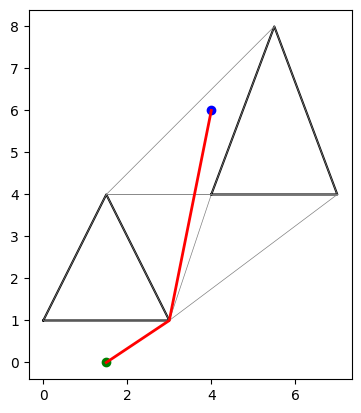

In [4]:
for poly in polys:
    xs = [p.x for p in poly] + [poly[0].x]
    ys = [p.y for p in poly] + [poly[0].y]
    plt.plot(xs, ys, 'k-')

for edge in g.visgraph.edges:
    x = [edge.p1.x, edge.p2.x]
    y = [edge.p1.y, edge.p2.y]
    plt.plot(x, y, 'gray', linewidth=0.5)

px = [p.x for p in path]
py = [p.y for p in path]
plt.plot(px, py, 'r-', linewidth=2)


plt.scatter([start.x], [start.y], color='green')
plt.scatter([end.x], [end.y], color='blue')

plt.gca().set_aspect('equal')
plt.show()

<h2 style="color:rgb(0,120,170)">2. RRT* (Rapidly-exploring Random Tree Star)</h2>

The **RRT** algorithm searches complex high-dimensional spaces by building a space-filling tree from random samples. Constructed incrementally, the tree is inherently biased to expand toward the largest unsearched regions of the configuration space.

**RRT\*** extends RRT: when a new node is added, it picks the neighbour that gives the cheapest connection and **rewires** nearby nodes through it if that shortens their paths. As the number of samples grows, the path converges toward the optimal one.

In [5]:
from RRT_star import RRTStar
from shapely.geometry import Polygon

### Step 1: Grow the tree
Define the same obstacles and start/goal points, then run RRT\*. The path is read from the tree by following parent links from the goal back to the start.

In [7]:
polygons = [
    [(0,1), (3,1), (1.5,4)],
    [(4,4), (7,4), (5.5,8)]
]

obstacles = [Polygon(p) for p in polygons]

start = (1.5, 0)
goal = (4, 6)

rrt = RRTStar(start, goal, obstacles)
path = rrt.plan()
print(path)

[array([1.5, 0. ]), array([2.09343772, 0.73645665]), array([3.02764282, 0.74544161]), array([3.21790031, 1.20782899]), array([3.13707042, 1.70125227]), array([3.21499732, 2.48213573]), array([3.42190059, 2.93731815]), array([3.87014737, 3.15884652]), array([3.89297564, 3.65832511]), array([3.76168007, 4.14077871]), array([3.32309281, 4.38086456]), array([3.51595081, 4.84217334]), array([3.76414904, 5.27622131]), array([4.08573696, 5.65908057]), array([4., 6.])]


### Step 2: Visualize
Gray: tree edges. Red: found path. Green: start. Blue: goal.

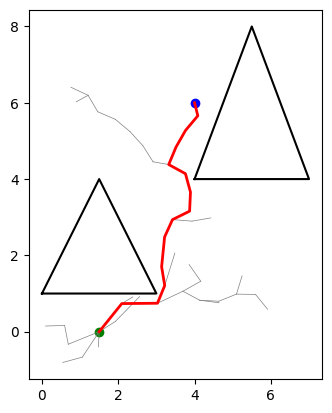

In [8]:
for poly in polygons:
    xs = [p[0] for p in poly] + [poly[0][0]]
    ys = [p[1] for p in poly] + [poly[0][1]]
    plt.plot(xs, ys, 'k-')

for node in rrt.nodes:
    if node.parent:
        plt.plot([node.x, node.parent.x],
                 [node.y, node.parent.y],
                 'gray', linewidth=0.5)

if path:
    px = [p[0] for p in path]
    py = [p[1] for p in path]
    plt.plot(px, py, 'r-', linewidth=2)

plt.scatter([start[0]], [start[1]], color='green')
plt.scatter([goal[0]], [goal[1]], color='blue')

plt.gca().set_aspect('equal')
plt.show()

<h2 style="color:rgb(0,120,170)">3. PRM (Probabilistic Roadmap)</h2>

A **probabilistic roadmap (PRM)** is a network graph of possible paths in a given map based on free and occupied spaces. The graph is built by randomly sampling points from the configuration space, testing the samples to see whether they are in the free space, and using a local planner to attempt to connect these configurations to other nearby configurations.

Once built, the roadmap can be reused: new start and goal points only need to be connected to it before running a graph search.

In [9]:
from PRM import PRM
from shapely.geometry import Polygon, LineString, Point


### Step 1: Define the map
Same obstacles and start/goal points as before.

In [10]:
polygons = [
    [(0,1), (3,1), (1.5,4)],
    [(4,4), (7,4), (5.5,8)]
]

obstacles = [Polygon(p) for p in polygons]

start = (1.5, 0)
goal = (4, 6)

### Step 2: Build the roadmap and find the path
Sample free points, connect each to its k nearest neighbours if the line between them is collision-free, then search the roadmap with Dijkstra's algorithm.

In [11]:
prm = PRM(obstacles, n_samples=250, k=8)
path = prm.plan(start, goal)

### Step 3: Visualize
Gray: roadmap edges. Red: found path. Green: start. Blue: goal.

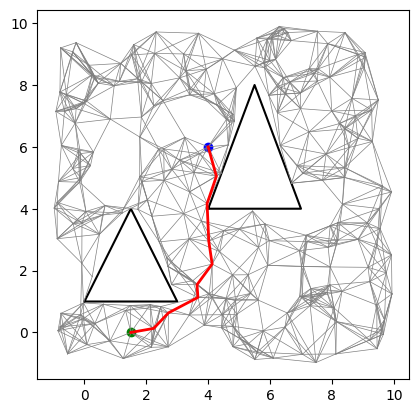

In [12]:
for poly in polygons:
    xs = [p[0] for p in poly] + [poly[0][0]]
    ys = [p[1] for p in poly] + [poly[0][1]]
    plt.plot(xs, ys, 'k-')

for u, v in prm.graph.edges:
    plt.plot([u[0], v[0]], [u[1], v[1]],
             'gray', linewidth=0.5)

px = [p[0] for p in path]
py = [p[1] for p in path]
plt.plot(px, py, 'r-', linewidth=2)

plt.scatter([start[0]], [start[1]], color='green')
plt.scatter([goal[0]], [goal[1]], color='blue')

plt.gca().set_aspect('equal')
plt.show()